# Lab 7 · Example B — Reuters Topic Classification with a Bidirectional LSTM
### Deep Learning Laboratory (23DS5PCDLG) · Student Fill-in Notebook

**Why a second example?** Same ingredients (Embedding → Bidirectional LSTM → Dense), but now the
task has **46 topic classes**, not 2. This shows how the **output layer and loss change** when you
move from *binary* to *multi-class* classification. Spot the differences from Example A!

| | Example A (IMDB) | Example B (Reuters) |
|---|---|---|
| classes | 2 (pos/neg) | **46 topics** |
| output layer | `Dense(1, 'sigmoid')` | **`Dense(46, 'softmax')`** |
| loss | `binary_crossentropy` | **`sparse_categorical_crossentropy`** |

---
Replace every `None  # TODO (Qn)`. Run top to bottom. *(Downloads the Reuters dataset once.)*


## Step 0 — Imports *(given)*

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Bidirectional, Dense, Dropout, Input
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.datasets import reuters
import matplotlib.pyplot as plt
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## Task 1 — Load and pad the data

Reuters newswires are also pre-encoded as integer indices, each labelled with one of 46 topics.
Keep the top `num_words` words, pad to `maxlen`, and use the built-in test split.

*Hints:* keep 10000 words; pad to 200; count classes with `max(labels)+1`.


In [2]:
num_words = 10000     # TODO (Q1a): 10000
maxlen    = 200     # TODO (Q1a): 200

(X_train, y_train), (X_test, y_test) = reuters.load_data(num_words=num_words, test_split=0.2)

# Q1b) pad both sets
X_train = pad_sequences(X_train, maxlen=maxlen)   # TODO (Q1b): maxlen
X_test  = pad_sequences(X_test,  maxlen=maxlen)   # TODO (Q1b): maxlen

# Q1c) how many topic classes? (labels are integers 0..45)
num_classes = int(max(y_train)) + 1   # TODO (Q1c): int(max(y_train)) + 1
print("X_train:", X_train.shape, " classes:", num_classes)

2110848/2110848 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
X_train: (8982, 200)  classes: 46


#### Quick check *(given)*

In [3]:
assert X_train.shape[1] == 200, "pad reviews to length 200"
assert num_classes == 46, "Reuters has 46 topic classes"
print("Task 1 looks correct ✔")

Task 1 looks correct ✔


## Task 2 — Build the model (multi-class head)

Same backbone as Example A, but the **output** changes for 46 classes.

*Hints:* `Embedding(num_words, 128)`; `Bidirectional(LSTM(64, return_sequences=False))`;
output is `Dense(num_classes, activation='softmax')` — one neuron per topic.


In [4]:
model = Sequential()
model.add(Input(shape=(maxlen,)))

# Q2a) Embedding
model.add(Embedding(input_dim=num_words, output_dim=128))   # TODO (Q2a): num_words, 128

# Q2b) Bidirectional LSTM -> one summary vector
model.add(Bidirectional(LSTM(64, return_sequences=False)))   # TODO (Q2b): 64, False

model.add(Dropout(0.5))

# Q2c) Output: one neuron PER CLASS with softmax
model.add(Dense(num_classes, activation='softmax'))   # TODO (Q2c): num_classes, 'softmax'

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 46)             │         5,934 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,384,750 (5.28 MB)

 Trainable params: 1,384,750 (5.28 MB)

 Non-trainable params: 0 (0.00 B)

**Reflection Q2d.** Compare this `model.summary()` with Example A. Which layer changed size,
and why? (Hint: look at the final Dense layer's parameter count.)

> **Your answer (Q2d):** the Dense layer grew from (128+1)×1 to (128+1)×46 because ____.


## Task 3 — Compile and train (multi-class loss)

Labels here are **integers** (0–45), not one-hot — so use **`sparse_categorical_crossentropy`**
(it one-hots internally). Optimiser `adam`, track accuracy. Train ~10 epochs, batch 64, with a
20% validation split.


In [5]:
# Q3a) compile for integer multi-class labels
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',              # TODO (Q3a): 'sparse_categorical_crossentropy'
              metrics=['accuracy'])

# Q3b) train with a validation split
history = model.fit(X_train, y_train,
                    validation_split=0.2,   # TODO (Q3b): 0.2
                    epochs=10,             # TODO (Q3b): 10
                    batch_size=64)         # TODO (Q3b): 64

Epoch 1/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 59s 483ms/step - accuracy: 0.4152 - loss: 2.4037 - val_accuracy: 0.5047 - val_loss: 1.9804
Epoch 2/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 53s 469ms/step - accuracy: 0.5132 - loss: 1.8819 - val_accuracy: 0.5531 - val_loss: 1.7202
Epoch 3/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 85s 501ms/step - accuracy: 0.5328 - loss: 1.8062 - val_accuracy: 0.5426 - val_loss: 1.7437
Epoch 4/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 56s 500ms/step - accuracy: 0.5672 - loss: 1.6560 - val_accuracy: 0.5771 - val_loss: 1.6654
Epoch 5/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 80s 481ms/step - accuracy: 0.6046 - loss: 1.5545 - val_accuracy: 0.5910 - val_loss: 1.6301
Epoch 6/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 55s 485ms/step - accuracy: 0.5997 - loss: 1.5345 - val_accuracy: 0.4068 - val_loss: 1.8443
Epoch 7/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 82s 487ms/step - accuracy: 0.6046 - loss: 1.4696 - val_accuracy: 0.5899 - val_loss: 1.6173
Epoch 8/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 55s 485ms/step - accuracy: 0.6850 - loss: 1

## Task 4 — Evaluate and plot *(fill the blanks)*

71/71 ━━━━━━━━━━━━━━━━━━━━ 4s 53ms/step - accuracy: 0.6398 - loss: 1.5496
Test accuracy: 63.98%


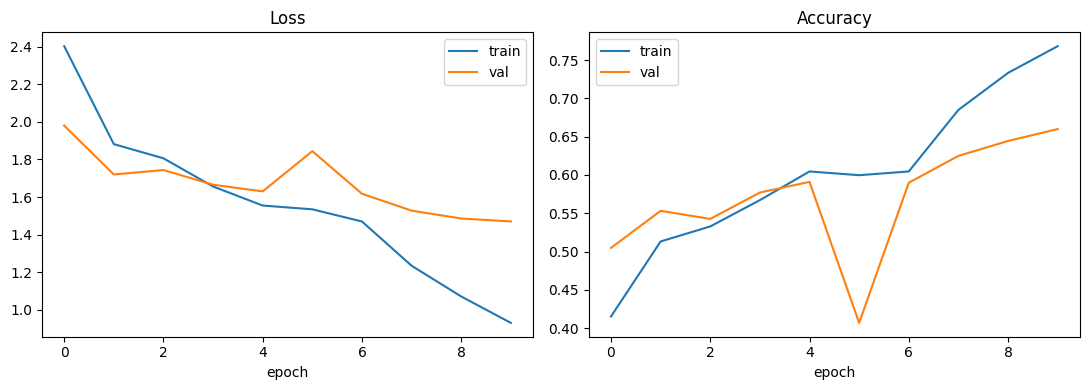

In [6]:
loss, accuracy = model.evaluate(X_test, y_test)
print(f"Test accuracy: {accuracy*100:.2f}%")   # expect ~ 65-72%

plt.figure(figsize=(11,4))
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val')      # TODO (Q4a): 'val_loss'
plt.title('Loss'); plt.xlabel('epoch'); plt.legend()
plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')      # TODO (Q4b): 'val_accuracy'
plt.title('Accuracy'); plt.xlabel('epoch'); plt.legend()
plt.tight_layout(); plt.show()

## Task 5 — Inspect a prediction *(fill the blank)*

For multi-class, the prediction is the class with the **highest** softmax probability.


In [7]:
probs = model.predict(X_test[:5], verbose=0)   # shape (5, 46)

# Q5) pick the most likely topic for each review
pred_classes = np.argmax(probs, axis=1)   # TODO (Q5): np.argmax(probs, axis=1)

for i in range(5):
    print(f"true topic: {y_test[i]:2d}   predicted: {pred_classes[i]:2d}")

true topic:  3   predicted:  3
true topic: 10   predicted: 19
true topic:  1   predicted:  1
true topic:  4   predicted:  4
true topic:  4   predicted: 13


## Task 6 — Short questions *(write answers here)*

1. What are the **three** differences between this model and Example A (output units, activation,
   loss)?
2. Why `sparse_categorical_crossentropy` here instead of `categorical_crossentropy`? (Hint: are
   the labels one-hot or integers?)
3. The Embedding and Bidirectional LSTM layers are **identical** to Example A. What does that tell
   you about reusing a sequence backbone across tasks?
4. Multi-class accuracy (~68%) is lower than IMDB (~87%). Give one reason why 46-way is harder than
   2-way.

> **Your answers:**
> 1. **Output Units**: 46 units (one for each topic class) instead of 1 unit. **Activation**: `softmax` instead of `sigmoid`. **Loss**: `sparse_categorical_crossentropy` instead of `binary_crossentropy`.
> 2. Because the labels are provided as **integers** (0 to 45) rather than one-hot encoded vectors. `sparse_categorical_crossentropy` is computationally more efficient and convenient for integer targets.
> 3. It demonstrates that the sequence-processing backbone (Embedding + LSTM) is highly **reusable** and learns generalizable representation features of sequential data, which can then be mapped to completely different downstream heads (binary vs. multi-class classification).
> 4. Classifying into 46 classes is harder because: (a) random guessing probability is much lower (1/46 ≈ 2.2% vs 50%), (b) the decision boundaries are highly complex with substantial semantic overlap between multiple topics, and (c) the dataset has highly imbalanced classes with very few samples for some of the 46 topics.